In [2]:
import os 
import cv2 
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image



In [3]:
print(os.getcwd())
print(os.listdir())

c:\Users\User\Documents\tensor_py_engineer_stuff\eda_image
['eda_iamge.ipynb', 'Healthy.png', 'Mild_DR.png', 'Moderate_DR_10.png', 'Proliferate DR_108.png', 'Severe_DR.png']


Healthy (256, 256, 3)


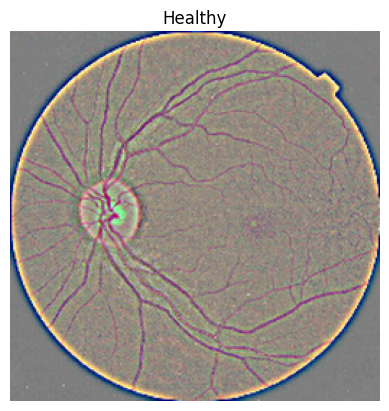

Mild DR (256, 256, 3)


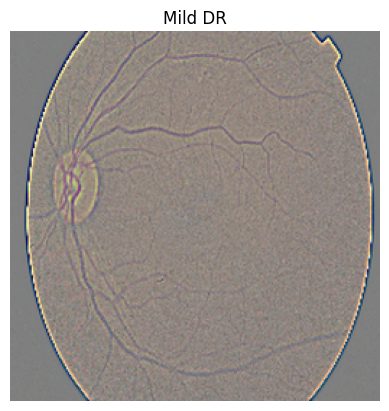

Moderate DR (256, 256, 3)


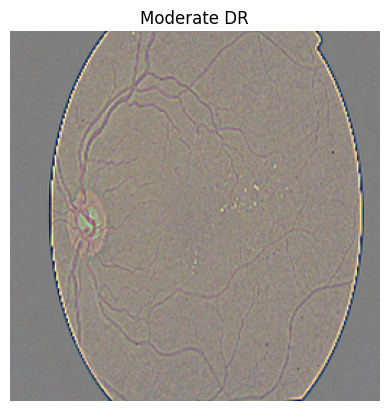

Proliferative DR (256, 256, 3)


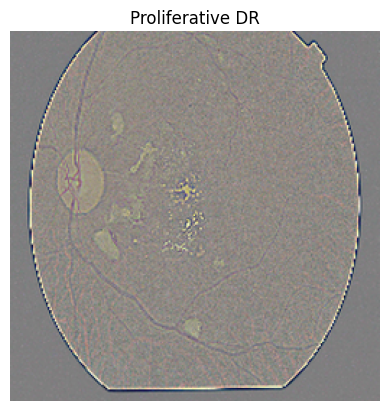

Severe DR (256, 256, 3)


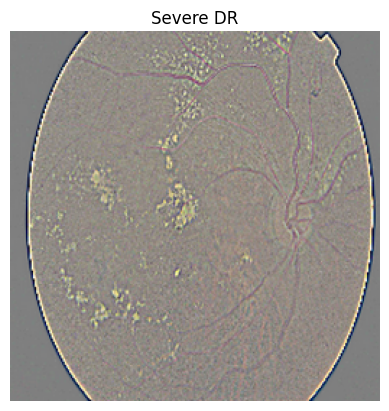

In [4]:
image_paths = [
    "Healthy.png",
    "Mild_DR.png",
    "Moderate_DR_10.png",
    "Proliferate DR_108.png",
    "Severe_DR.png"
]

labels = [
    "Healthy",
    "Mild DR",
    "Moderate DR",
    "Proliferative DR",
    "Severe DR"
]

for path, label in zip(image_paths, labels):
    img = Image.open(path).convert("RGB")
    arr = np.array(img)

    print(label, arr.shape)

    plt.imshow(img)
    plt.title(label)
    plt.axis("off")
    plt.show()

In [5]:
stats = []

for path, label in zip(image_paths, labels):
    img = Image.open(path).convert("RGB")
    arr = np.array(img)
    
    
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    
    stats.append({
        "label": label,
        "shape": arr.shape,
        "min_pixel": arr.min(),
        "max_pixel": arr.max(),
        "mean_R": arr[:, :, 0].mean(),
        "mean_G": arr[:, :, 1].mean(),
        "mean_B": arr[:, :, 2].mean(),
        "std_R": arr[:, :, 0].std(),
        "std_G": arr[:, :, 1].std(),
        "std_B": arr[:, :, 2].std(),
        "gray_mean": gray.mean(),
        "gray_std": gray.std()

    })
   
df_stats = pd.DataFrame(stats)
df_stats 
    

,label,shape,min_pixel,max_pixel,mean_R,mean_G,mean_B,std_R,std_G,std_B,gray_mean,gray_std
0,Healthy,"(256, 256, 3)",0,255,143.055969,134.614426,127.322357,31.384513,27.080510,10.752508,136.307770,24.111030
1,Mild DR,"(256, 256, 3)",0,255,141.363113,133.241623,127.824631,19.538449,14.555236,7.319293,135.050278,14.416446
2,Moderate DR,"(256, 256, 3)",0,255,143.122589,135.585007,128.869293,19.078409,15.504292,7.036628,137.072784,14.652430
3,Proliferative DR,"(256, 256, 3)",0,255,139.605774,134.960754,130.651733,19.677199,15.905347,9.193546,135.860977,15.553705
4,Severe DR,"(256, 256, 3)",0,255,143.738113,137.848465,131.335312,21.704940,19.556020,11.992404,138.866837,18.673299


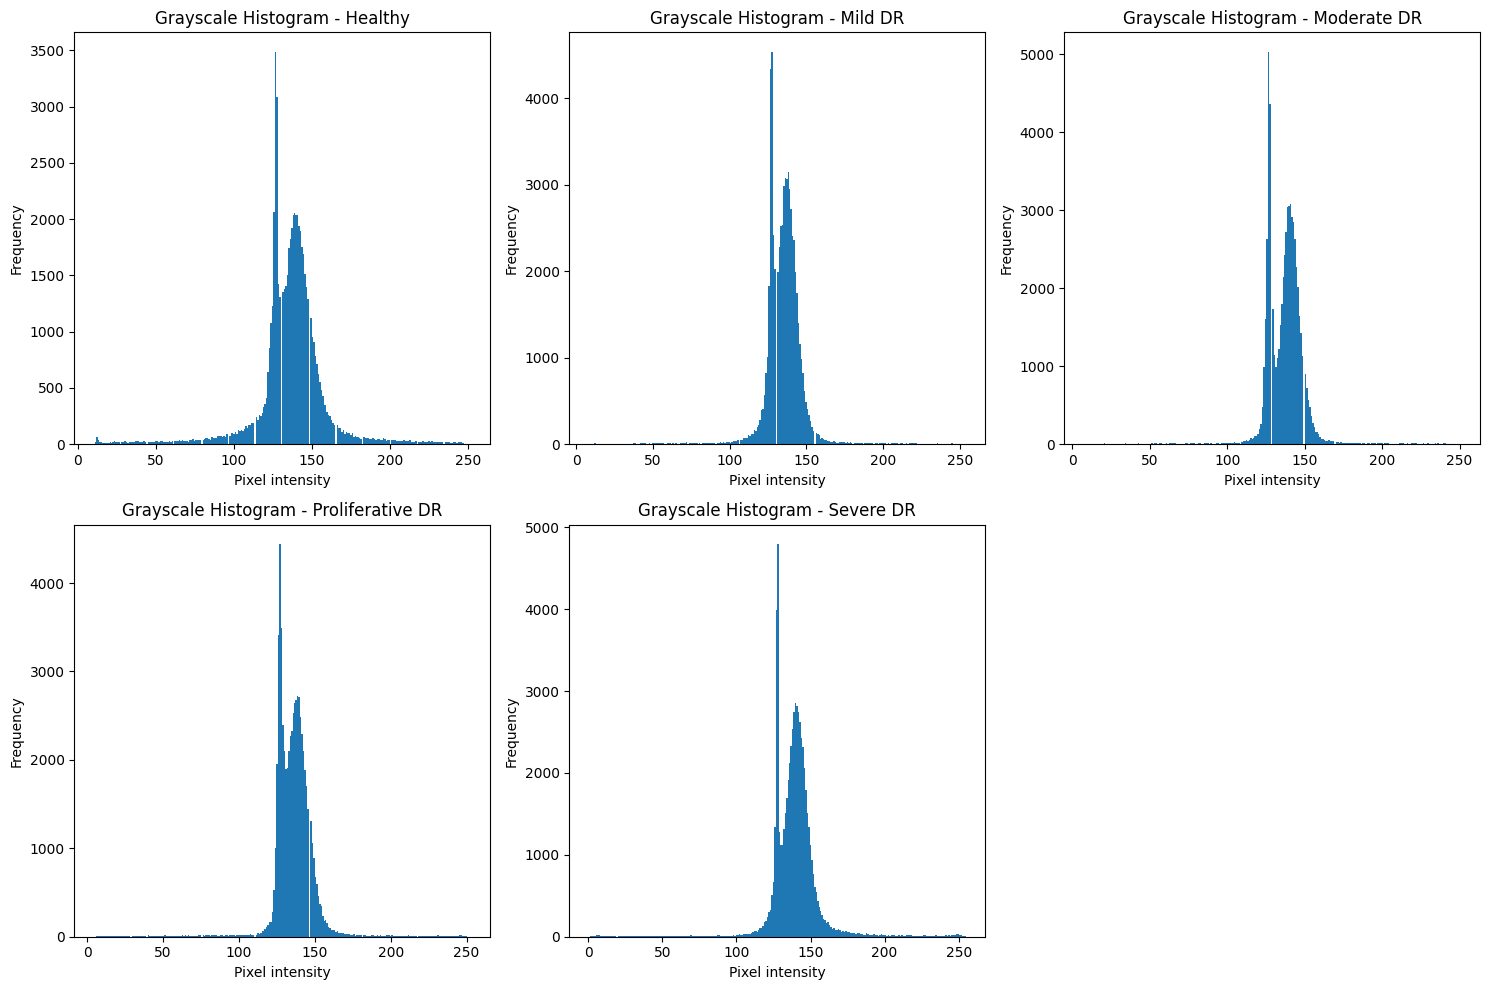

In [6]:
plt.figure(figsize=(15, 10))

for i, (path, label) in enumerate(zip(image_paths, labels)):
    img = Image.open(path).convert("RGB")
    arr = np.array(img)
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)

    plt.subplot(2, 3, i + 1)
    plt.hist(gray.ravel(), bins=256)
    plt.title(f"Grayscale Histogram - {label}")
    plt.xlabel("Pixel intensity")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

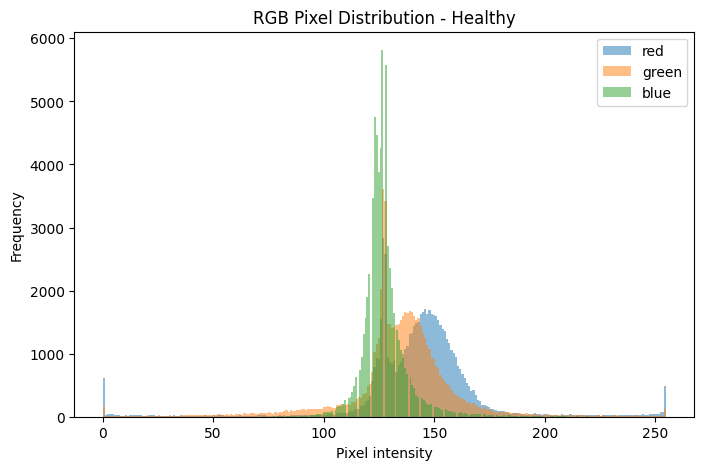

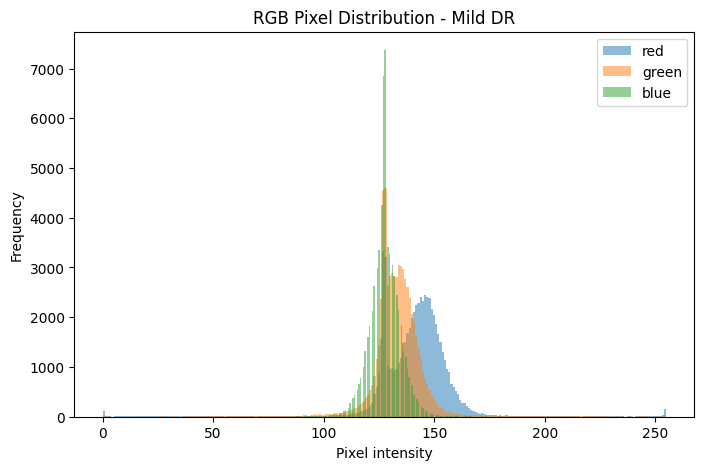

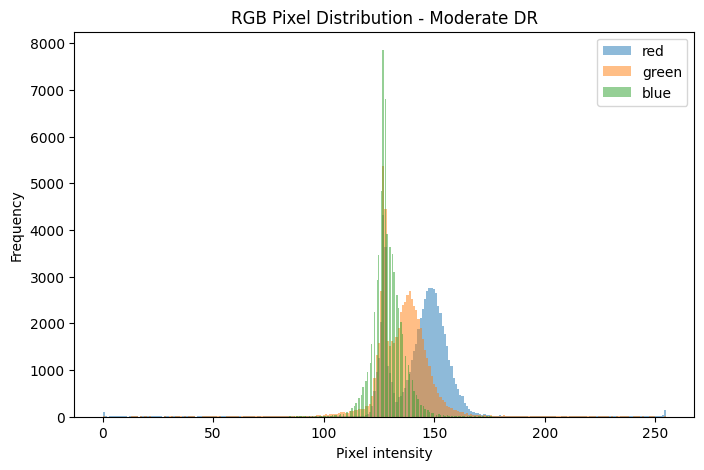

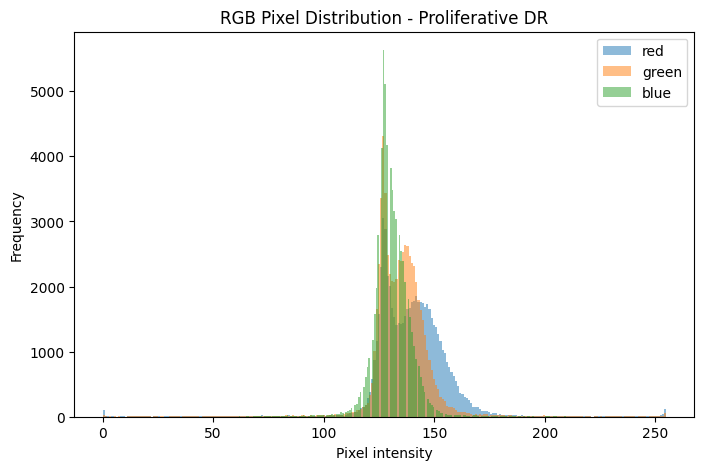

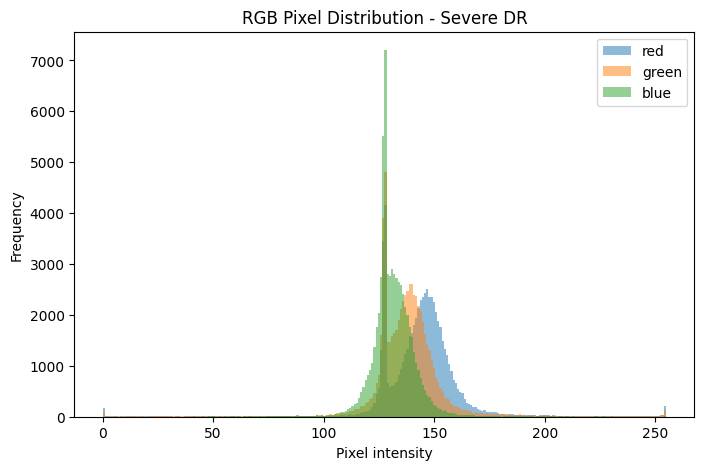

In [7]:
colors = ["red", "green", "blue"]

for path, label in zip(image_paths, labels):
    img = Image.open(path).convert("RGB")
    arr = np.array(img)

    plt.figure(figsize=(8, 5))

    for channel in range(3):
        plt.hist(
            arr[:, :, channel].ravel(),
            bins=256,
            alpha=0.5,
            label=colors[channel]
        )

    plt.title(f"RGB Pixel Distribution - {label}")
    plt.xlabel("Pixel intensity")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

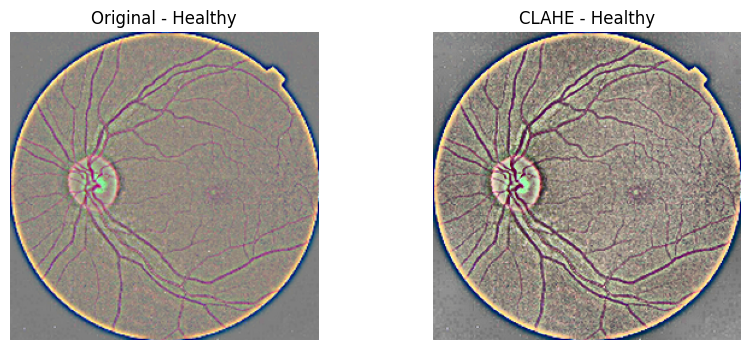

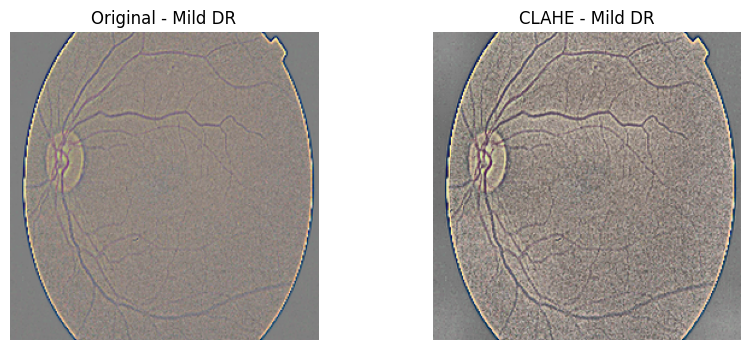

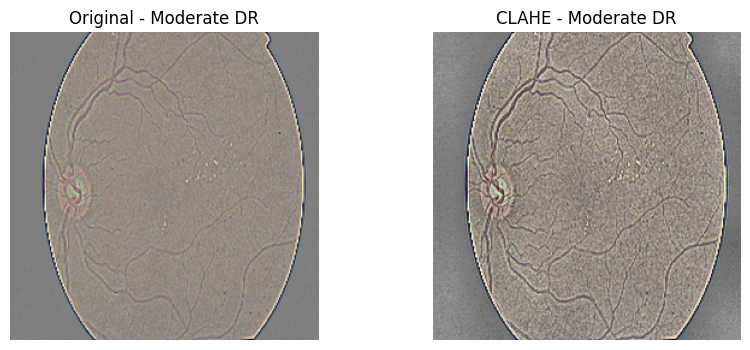

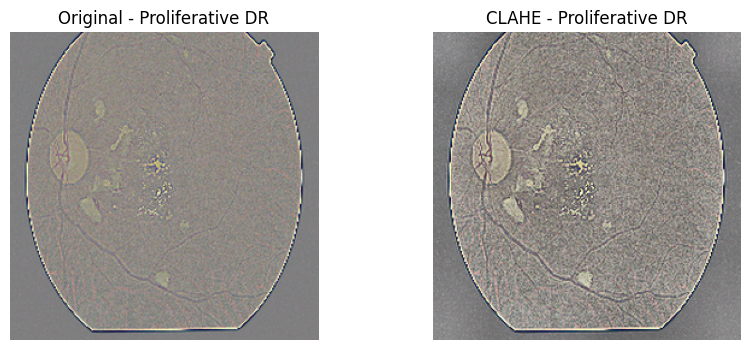

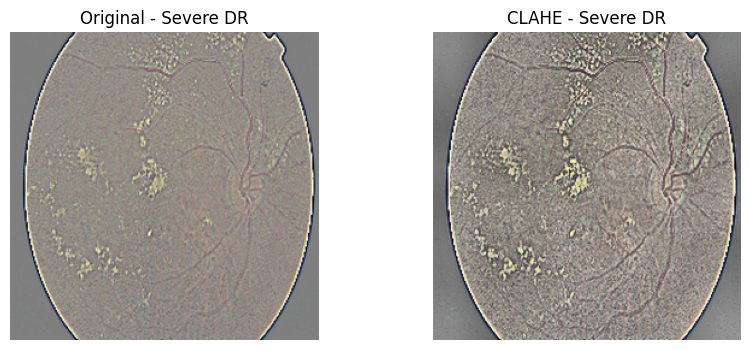

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def apply_clahe_rgb(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l_clahe = clahe.apply(l)

    lab_clahe = cv2.merge((l_clahe, a, b))
    img_clahe = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)

    return img, img_clahe


image_paths = [
    "Healthy.png",
    "Mild_DR.png",
    "Moderate_DR_10.png",
    "Proliferate DR_108.png",
    "Severe_DR.png"
]

labels = [
    "Healthy",
    "Mild DR",
    "Moderate DR",
    "Proliferative DR",
    "Severe DR"
]

for path, label in zip(image_paths, labels):
    original, clahe_img = apply_clahe_rgb(path)

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title(f"Original - {label}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(clahe_img)
    plt.title(f"CLAHE - {label}")
    plt.axis("off")

    plt.show()

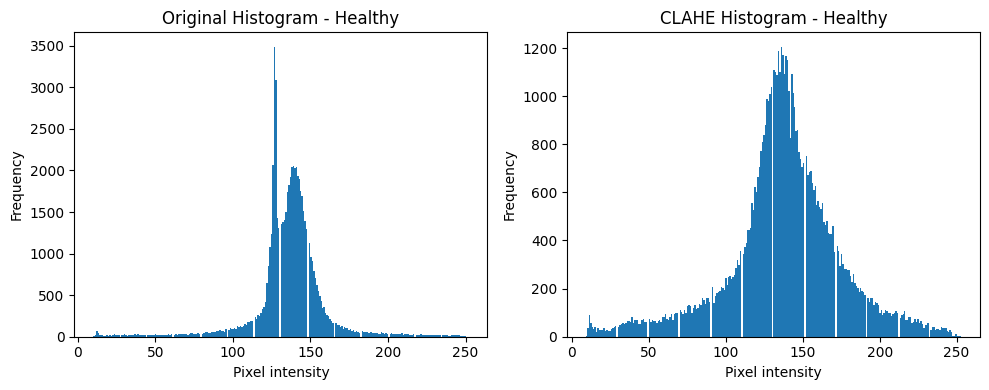

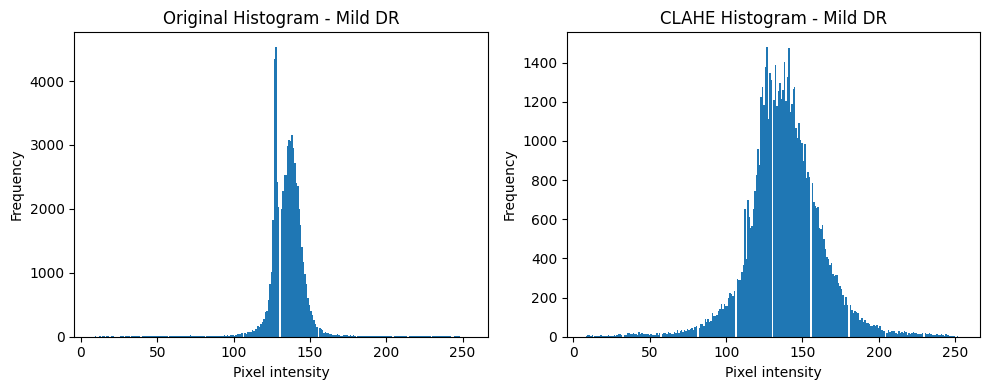

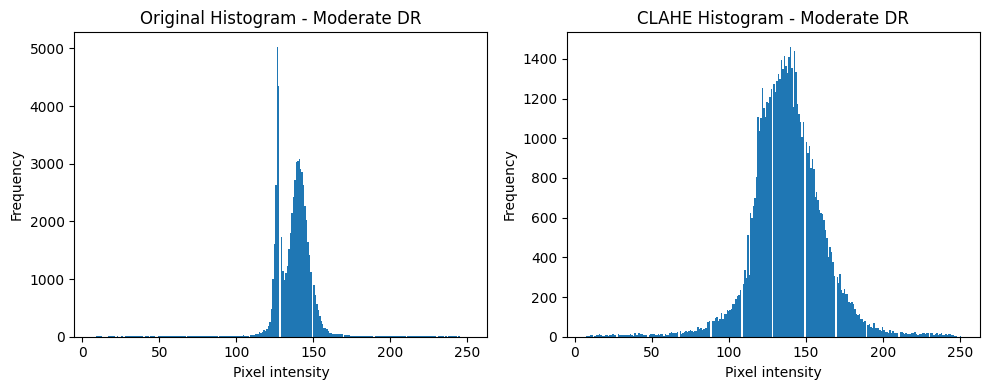

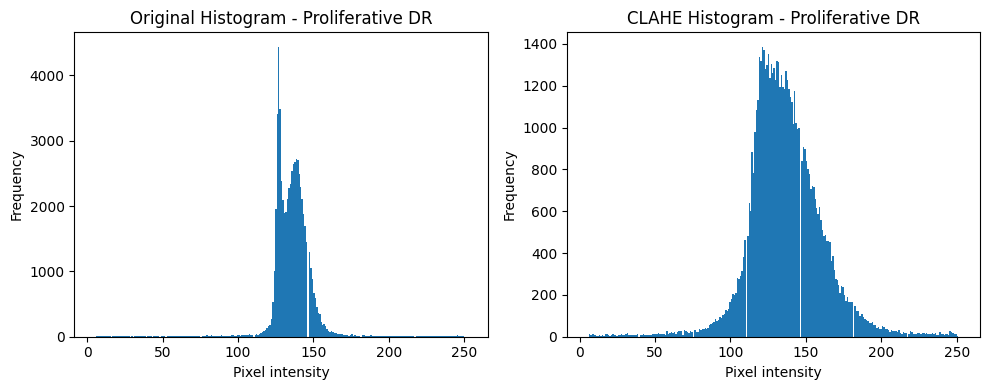

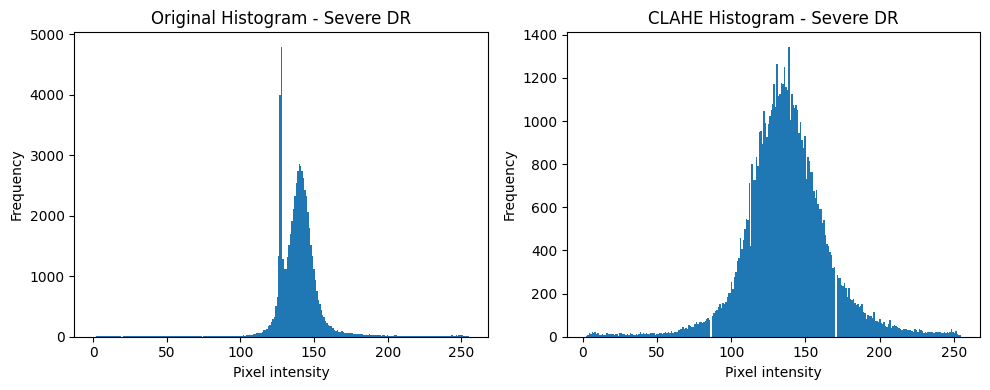

In [9]:
for path, label in zip(image_paths, labels):
    original, clahe_img = apply_clahe_rgb(path)

    gray_original = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    gray_clahe = cv2.cvtColor(clahe_img, cv2.COLOR_RGB2GRAY)

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.hist(gray_original.ravel(), bins=256)
    plt.title(f"Original Histogram - {label}")
    plt.xlabel("Pixel intensity")
    plt.ylabel("Frequency")

    plt.subplot(1, 2, 2)
    plt.hist(gray_clahe.ravel(), bins=256)
    plt.title(f"CLAHE Histogram - {label}")
    plt.xlabel("Pixel intensity")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

In [3]:
%pip install kagglehub 

Defaulting to user installation because normal site-packages is not writeable
  Using cached kagglehub-1.0.1-py3-none-any.whl.metadata (40 kB)
  Using cached kagglesdk-0.1.23-py3-none-any.whl.metadata (13 kB)
Using cached kagglehub-1.0.1-py3-none-any.whl (70 kB)
Using cached kagglesdk-0.1.23-py3-none-any.whl (217 kB)

   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   -------------------- ------------------- 1/2 [kagglehub]
   ---------------------------------------- 2/2 [kagglehub]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
%pip install rembg

Defaulting to user installation because normal site-packages is not writeable
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached scipy-1.17.1-cp312-cp312-win_amd64.whl.metadata (60 kB)
Using cached jsonschema-4.26.0-py3-none-any.whl (90 kB)
   ---------------------------------------- 0.0/12.3 MB ? eta -:--:--
    --------------------------------------- 0.3/12.3 MB ? eta -:--:--
   -- ------------------------------------- 0.8/12.3 MB 2.2 MB/s eta 0:00:06
   ---- ----------------------------------- 1.3/12.3 MB 2.2 MB/s eta 0:00:05
   ----- ---------------------------------- 1.8/12.3 MB 2.2 MB/s eta 0:00:05
   ------ --------------------------------- 2.1/12.3 MB 2.2 MB/s eta 0:00:05
   -------- ------------------------------- 2.6/12.3 MB 2.2 MB/s eta 0:00:05
   ---------- ----------------------------- 3.1/12.3 MB 2.2 MB/s eta 0:00:05
   ----------- ---------------------------- 3.7/12.3 MB 2.2 MB/s eta 0:00:04
   ------------ --------------------------- 3.9/

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
hipart 1.0.6 requires scipy<=1.15.3, but you have scipy 1.17.1 which is incompatible.
streamlit 1.39.0 requires packaging<25,>=20, but you have packaging 26.0 which is incompatible.
streamlit 1.39.0 requires pillow<11,>=7.1.0, but you have pillow 12.2.0 which is incompatible.
streamlit 1.39.0 requires protobuf<6,>=3.20, but you have protobuf 7.34.0 which is incompatible.

[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
import os
import cv2
import numpy as np
import pandas as pd
import kagglehub
from rembg import remove
from PIL import Image
from tqdm import tqdm

# ==========================================
# 1. DOWNLOAD DATASET
# ==========================================

path = kagglehub.dataset_download(
    "sachinkumar413/diabetic-retinopathy-dataset"
)

data_dir = path

print("Dataset path:", data_dir)
print("Folders:", os.listdir(data_dir))


# ==========================================
# 2. CREATE DATAFRAME
# ==========================================

filepaths = []
labels = []

for class_name in os.listdir(data_dir):
    class_path = os.path.join(data_dir, class_name)

    if os.path.isdir(class_path):
        for img_name in os.listdir(class_path):
            if img_name.lower().endswith((".jpg", ".jpeg", ".png")):
                filepaths.append(os.path.join(class_path, img_name))
                labels.append(class_name)

df = pd.DataFrame({
    "filepaths": filepaths,
    "labels": labels
})

print("\nInitial distribution:")
print(df["labels"].value_counts())
print("Total images:", len(df))


# ==========================================
# 3. PREPROCESS LIKE PAPER
# ==========================================

IMG_SIZE = 180

def preprocess_image_paper(img_path):
    # Load image
    img = Image.open(img_path).convert("RGB")

    # Background removal using REMBG
    img = remove(img)

    # Convert PIL -> NumPy
    img = np.array(img.convert("RGB"))

    # Grayscale conversion using OpenCV
    img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # Resize to 180x180
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    # Normalize
    img = img.astype("float32") / 255.0

    # Add channel dimension: (180, 180, 1)
    img = np.expand_dims(img, axis=-1)

    return img


# ==========================================
# 4. APPLY PREPROCESSING
# ==========================================

X = []
y = []

for _, row in tqdm(df.iterrows(), total=len(df)):
    try:
        img = preprocess_image_paper(row["filepaths"])
        X.append(img)
        y.append(row["labels"])
    except Exception as e:
        print("Error:", row["filepaths"], e)

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

No onnxruntime backend found.
Please install rembg with CPU or GPU support:

    pip install "rembg[cpu]"  # for CPU
    pip install "rembg[gpu]"  # for NVIDIA/CUDA GPU

For more information, see: https://github.com/danielgatis/rembg#installation


SystemExit: 1

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\IPython\core\interactiveshell.py:3707: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
import matplotlib.pyplot as plt

idx = 0

original = Image.open(df["filepaths"].iloc[idx]).convert("RGB")
processed = preprocess_image_paper(df["filepaths"].iloc[idx])

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed.squeeze(), cmap="gray")
plt.title("Paper preprocessing")
plt.axis("off")

plt.show()